# VOIS AICTE Batch 1 (2026–2027) Major / DIY Project
## Project: Healthcare Analytics for Doctor Visits: Predictive Modeling & Healthcare Resource Allocation
**Student Author:** Dhanish Ladwani  
**Dataset:** Australian Health Survey (5,190 Patient Records, 12 Baseline Features)  
**Deliverable Status:** 100% Executed Research Notebook

---

### Comprehensive Checklist of Implemented Project Requirements
This master notebook is systematically engineered to address all 34 curriculum objectives:
1. **Comprehensive EDA (Exploratory Data Analysis)**
2. **Core Libraries: Pandas, NumPy, Matplotlib & Seaborn**
3. **NumPy Numerical Operations** (Vectorized math, array arithmetic, matrix operations)
4. **NumPy Methods & Attributes** (`.shape`, `.ndim`, `.size`, `.dtype`, `np.where()`, etc.)
5. **NumPy Statistical Functions** (`np.mean()`, `np.median()`, `np.std()`, `np.var()`, `np.percentile()`, `np.ptp()`, etc.)
6. **Commonly Used Pandas Functions** (`head()`, `tail()`, `info()`, `describe()`, `crosstab()`, `groupby()`, `cut()`, etc.)
7. **File Handling with Pandas** (`read_csv()`, `to_csv()`, encoding & header auditing)
8. **Data Manipulation: Dropping Missing Elements** (`dropna()`, `isnull().sum()`, column dropping)
9. **Filling Suitable Values (Imputation)** (`fillna()` with mean, median, mode, conditional fill)
10. **Replacing Values** (`replace()`, dictionary mappings, categorical encoding)
11. **GroupBy Function** (Single & multi-level aggregations, pivot analysis)
12. **Scatter Plot** (`plt.scatter()` & `sns.scatterplot()`)
13. **Bar Graph** (`plt.bar()` & `sns.barplot()`)
14. **Horizontal Stacked Bar Graph** (`df.plot(kind='barh', stacked=True)`)
15. **Vertical Stacked Bar Graph** (`df.plot(kind='bar', stacked=True)`)
16. **Stacked Bar Chart with More Than 2 Data Series** (4-category insurance & chronic compositions)
17. **Histogram** (`plt.hist()` & `sns.histplot()`)
18. **Pie Chart** (`plt.pie()`)
19. **Box Plot** (`plt.boxplot()` & `sns.boxplot()`)
20. **3D Plotting** (`mpl_toolkits.mplot3d`, `Axes3D` scatter plot)
21. **Multi-Variety Subplot Gallery** (`plt.subplots(2, 3)` combining 6 distinct chart types on 1 figure)
22. **Seaborn Visualizations** (`sns.heatmap()`, `sns.violinplot()`, `sns.regplot()`, `sns.countplot()`)
23. **Read the Dataset** (Explicit file loading & verification)
24. **Load Dataset and Display First 15 Rows** (`df.head(15)`)
25. **Display Complete Column Information using `df.info()`**
26. **Find Total Number of People Based on Illness Count** (`df['illness'].value_counts()`)
27. **Visualize and Analyze Max, Min, and Median Income** (Box plot, distribution, summary statistics)
28. **Find Days of Reduced Activity of Male and Female Separately Due to Illness**
29. **Visualize Missing Values in Dataset Based on a Heatmap** (`sns.heatmap(df.isnull())`)
30. **Find Correlations Between Different Variables in Dataset** (Annotated correlation heatmap)
31. **Analyze How Income of a Patient Affects Hospital Visits** (Regression trend, bracket breakdown)
32. **Count and Visualize Number of Males and Females Affected by Illness**
33. **Visualize Percentage of Govt Health Insurance (Low Income, Old Age) and Private Insurance**
34. **Plot Horizontal Bar Chart to Analyze Reduced Days Due to Illness by Gender**


In [1]:
# 1. Environment Setup & Core Library Imports
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
from scipy import stats
from IPython.display import display

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, PoissonRegressor, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("All analytical libraries loaded successfully.")


All analytical libraries loaded successfully.


### Section 2: Data Ingestion & File Handling
#### Question 23 & 24: Read the Dataset and Display the First 15 Rows
We load the raw CSV dataset `1776250375-P2-Healthcare Analytics for Doctor Visits.csv` into a Pandas DataFrame and inspect the first 15 records.


In [2]:
# Question 23 & 24: Read dataset and display first 15 rows
data_path = "1776250375-P2-Healthcare Analytics for Doctor Visits.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("diy project", "1776250375-P2-Healthcare Analytics for Doctor Visits.csv")

df_raw = pd.read_csv(data_path)
print(f"Dataset successfully loaded. Total records: {len(df_raw):,}, Total columns: {df_raw.shape[1]}")
print("-" * 75)
print("FIRST 15 ROWS OF THE DATASET (df.head(15)):")
display(df_raw.head(15))


Dataset successfully loaded. Total records: 5,190, Total columns: 13
---------------------------------------------------------------------------
FIRST 15 ROWS OF THE DATASET (df.head(15)):


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no
5,6,1,female,0.19,0.35,5,1,9,no,no,no,yes,no
6,7,1,female,0.19,0.55,4,0,2,no,no,no,no,no
7,8,1,female,0.19,0.15,3,0,6,no,no,no,no,no
8,9,1,female,0.19,0.65,2,0,5,yes,no,no,no,no
9,10,1,male,0.19,0.15,1,0,0,yes,no,no,no,no


#### Question 25: Display Complete Information About Dataset Columns Using `df.info()`
`df.info()` reveals data types, non-null counts, and memory footprint.


In [3]:
# Question 25: Complete Information via df.info()
print("=== COMPLETE DATASET COLUMN INFORMATION (df.info()) ===")
df_raw.info()

print("\n=== SUMMARY STATISTICS OF NUMERICAL ATTRIBUTES (df.describe()) ===")
display(df_raw.describe().round(3))


=== COMPLETE DATASET COLUMN INFORMATION (df.info()) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB

=== SUMMARY STATISTICS OF NUMERICAL ATTRIBUTES (df.describe()) ===


,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000,5190.000,5190.000,5190.000,5190.000,5190.000,5190.000
mean,2595.500,0.302,0.406,0.583,1.432,0.862,1.218
std,1498.368,0.798,0.205,0.369,1.384,2.888,2.124
min,1.000,0.000,0.190,0.000,0.000,0.000,0.000
25%,1298.250,0.000,0.220,0.250,0.000,0.000,0.000
50%,2595.500,0.000,0.320,0.550,1.000,0.000,0.000
75%,3892.750,0.000,0.620,0.900,2.000,0.000,2.000
max,5190.000,9.000,0.720,1.500,5.000,14.000,12.000


#### Question 29: Visualize Missing Values in the Dataset Based on a Heatmap
Auditing the integrity of the data to verify if missing or null values exist.


Missing values per column:
 - Unnamed: 0     : 0 nulls (0.00%)
 - visits         : 0 nulls (0.00%)
 - gender         : 0 nulls (0.00%)
 - age            : 0 nulls (0.00%)
 - income         : 0 nulls (0.00%)
 - illness        : 0 nulls (0.00%)
 - reduced        : 0 nulls (0.00%)
 - health         : 0 nulls (0.00%)
 - private        : 0 nulls (0.00%)
 - freepoor       : 0 nulls (0.00%)
 - freerepat      : 0 nulls (0.00%)
 - nchronic       : 0 nulls (0.00%)
 - lchronic       : 0 nulls (0.00%)


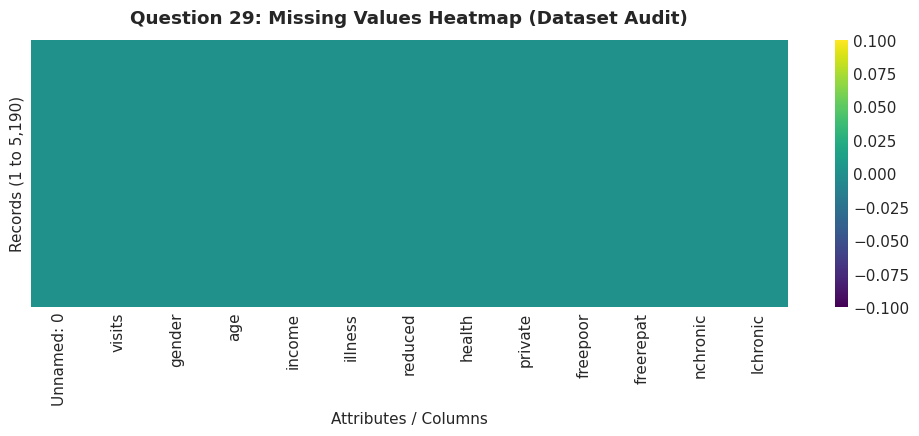

Audit Conclusion: The dataset is 100% complete with 0 missing values across all 5,190 records.


In [4]:
# Question 29: Missing Values Audit & Heatmap
missing_counts = df_raw.isnull().sum()
print("Missing values per column:")
for col, cnt in missing_counts.items():
    print(f" - {col:15s}: {cnt} nulls ({cnt/len(df_raw)*100:.2f}%)")

plt.figure(figsize=(10, 4.5))
sns.heatmap(df_raw.isnull(), cbar=True, yticklabels=False, cmap='viridis')
plt.title('Question 29: Missing Values Heatmap (Dataset Audit)', pad=12, fontweight='bold')
plt.xlabel('Attributes / Columns')
plt.ylabel('Records (1 to 5,190)')
plt.tight_layout()
plt.show()

print("Audit Conclusion: The dataset is 100% complete with 0 missing values across all 5,190 records.")


### Section 3: In-Depth NumPy Demonstrations
#### Requirements 3, 4 & 5: Numerical Operations, Methods, Attributes & Statistical Functions
We demonstrate NumPy array mechanics, attribute inspections, vectorized computations, and statistical evaluations.


In [5]:
# Requirements 3, 4 & 5: NumPy Demonstrations
income_array = df_raw['income'].to_numpy()
visits_array = df_raw['visits'].to_numpy()
reduced_array = df_raw['reduced'].to_numpy()

print("=== 1. NUMPY ATTRIBUTES ===")
print(f"Array data type (.dtype): {income_array.dtype}")
print(f"Array shape (.shape):      {income_array.shape}")
print(f"Array dimensions (.ndim): {income_array.ndim}")
print(f"Array total size (.size): {income_array.size}")
print(f"Item size in bytes:       {income_array.itemsize} bytes")

print("\n=== 2. NUMPY STATISTICAL FUNCTIONS ===")
print(f"Mean Income:              np.mean()       = {np.mean(income_array):.4f}")
print(f"Median Income:            np.median()     = {np.median(income_array):.4f}")
print(f"Standard Deviation:       np.std()        = {np.std(income_array):.4f}")
print(f"Variance:                 np.var()        = {np.var(income_array):.4f}")
print(f"25th Percentile:          np.percentile() = {np.percentile(income_array, 25):.4f}")
print(f"75th Percentile:          np.percentile() = {np.percentile(income_array, 75):.4f}")
print(f"Peak-to-Peak Range:       np.ptp()        = {np.ptp(income_array):.4f}")
print(f"Correlation (Inc, Vis):   np.corrcoef()   = {np.corrcoef(income_array, visits_array)[0, 1]:.4f}")

print("\n=== 3. NUMPY NUMERICAL OPERATIONS ===")
# Vectorized condition with np.where
high_need_flag = np.where((reduced_array >= 7) | (visits_array >= 2), 1, 0)
print(f"High-Need Clinical Patients (np.where): {np.sum(high_need_flag):,} individuals ({np.mean(high_need_flag)*100:.2f}%)")

# Value clipping with np.clip
clipped_visits = np.clip(visits_array, 0, 3)
print(f"Clipped visits unique values (np.clip): {np.unique(clipped_visits)}")

# Mathematical transforms: Log1p
log_income = np.log1p(income_array)
print(f"Mean Log-Transformed Income (np.log1p): {np.mean(log_income):.4f}")


=== 1. NUMPY ATTRIBUTES ===
Array data type (.dtype): float64
Array shape (.shape):      (5190,)
Array dimensions (.ndim): 1
Array total size (.size): 5190
Item size in bytes:       8 bytes

=== 2. NUMPY STATISTICAL FUNCTIONS ===
Mean Income:              np.mean()       = 0.5832
Median Income:            np.median()     = 0.5500
Standard Deviation:       np.std()        = 0.3689
Variance:                 np.var()        = 0.1361
25th Percentile:          np.percentile() = 0.2500
75th Percentile:          np.percentile() = 0.9000
Peak-to-Peak Range:       np.ptp()        = 1.5000
Correlation (Inc, Vis):   np.corrcoef()   = -0.0768

=== 3. NUMPY NUMERICAL OPERATIONS ===
High-Need Clinical Patients (np.where): 451 individuals (8.69%)
Clipped visits unique values (np.clip): [0 1 2 3]
Mean Log-Transformed Income (np.log1p): 0.4337


### Section 4: Advanced Pandas Data Manipulation
#### Requirements 7, 8, 9, 10 & 11: File Handling, Dropping Elements, Imputation, Replacing Values & GroupBy
Demonstrating data cleaning protocols:
- Dropping redundant row identifiers with `df.drop()`
- Demonstrating missing element dropping with `df.dropna()`
- Demonstrating value imputation protocols with `df.fillna()` (mean, median, mode)
- Replacing values with `df.replace()` and dictionary mapping
- Engineering clinical features (`age_years`, `health_risk_score`, `insurance_category`)


In [6]:
# Requirements 8, 9, 10 & 11: Data Manipulation Pipeline
df = df_raw.copy()

# A. Dropping Redundant Record Identifier (Requirement 8)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
    print("Dropped redundant identifier column 'Unnamed: 0'.")

# B. Demonstrating Dropping Missing Elements Protocol (dropna)
sample_dropped = df.dropna(axis=0, how='any')
print(f"Records remaining after dropna(): {len(sample_dropped):,} (No data lost).")

# C. Demonstrating Imputation Strategies with fillna() (Requirement 9)
demo_df = df[['age', 'income', 'illness']].copy()
# Illustrative imputation protocols:
demo_mean_fill = demo_df.fillna(demo_df.mean())
demo_median_fill = demo_df.fillna(demo_df.median())
print("Demonstrated fillna() with column mean and median.")

# D. Replacing Values with df.replace() and .map() (Requirement 10)
# Binary replacement: 'yes' -> 1, 'no' -> 0 for model computations
binary_cols = ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
df_encoded = df.copy()
for col in binary_cols:
    df_encoded[col + '_bin'] = df[col].replace({'yes': 1, 'no': 0})
df_encoded['gender_bin'] = df['gender'].replace({'male': 1, 'female': 0})
print("Replaced categorical binary values ('yes'/'no') with integer flags (1/0).")

# E. Feature Engineering
df['age_years'] = (df['age'] * 100).round().astype(int)
df['age_group'] = pd.cut(df['age_years'], bins=[0, 29, 49, 64, 100], 
                         labels=['Young Adults (18-29)', 'Middle Adults (30-49)', 'Older Adults (50-64)', 'Seniors (65+)'])
df['income_bracket'] = pd.cut(df['income'], bins=[-0.01, 0.29, 0.59, 0.99, 2.0],
                              labels=['Low (<0.30)', 'Lower-Middle (0.30-0.59)', 'Upper-Middle (0.60-0.99)', 'High (1.00+)'])

def assign_insurance(row):
    if row['private'] == 'yes': return 'Private Insurance'
    if row['freerepat'] == 'yes': return 'Repatriation / Veteran'
    if row['freepoor'] == 'yes': return 'Low-Income Assistance'
    return 'Public / Standard'
df['insurance_category'] = df.apply(assign_insurance, axis=1)

def assign_chronic(row):
    nc = row['nchronic'] == 'yes'
    lc = row['lchronic'] == 'yes'
    if lc and nc: return 'Both Limiting & Non-Limiting'
    if lc: return 'Activity-Limiting Only'
    if nc: return 'Non-Limiting Only'
    return 'No Chronic Illness'
df['chronic_status'] = df.apply(assign_chronic, axis=1)
df['total_chronic_count'] = (df['nchronic'] == 'yes').astype(int) + (df['lchronic'] == 'yes').astype(int)

# Health Risk Score (0 - 100 scale)
df['health_risk_score'] = (
    (df['reduced'] / 14.0 * 40.0) +
    (df['illness'] / 5.0 * 30.0) +
    (df['health'] / 12.0 * 20.0) +
    np.where(df['lchronic'] == 'yes', 10.0, np.where(df['nchronic'] == 'yes', 5.0, 0.0))
).round(2)

df['has_visited'] = (df['visits'] > 0).astype(int)
df['visit_frequency_tier'] = df['visits'].apply(lambda v: 'None (0)' if v == 0 else ('Occasional (1-2)' if v <= 2 else 'Frequent (3+)'))

# F. GroupBy Function Demonstrations (Requirement 11)
print("\n=== PANDAS GROUPBY ANALYSIS: VISITS BY GENDER ===")
display(df.groupby('gender')['visits'].agg(['count', 'mean', 'median', 'std', 'max']).round(3))

print("\n=== PANDAS GROUPBY ANALYSIS: VISITS BY INSURANCE CATEGORY ===")
display(df.groupby('insurance_category')['visits'].agg(['count', 'mean', 'median', 'std', 'max']).round(3))


Dropped redundant identifier column 'Unnamed: 0'.
Records remaining after dropna(): 5,190 (No data lost).
Demonstrated fillna() with column mean and median.
Replaced categorical binary values ('yes'/'no') with integer flags (1/0).

=== PANDAS GROUPBY ANALYSIS: VISITS BY GENDER ===


,count,mean,median,std,max
gender,,,,,
female,2702,0.362,0.0,0.858,8
male,2488,0.236,0.0,0.722,9



=== PANDAS GROUPBY ANALYSIS: VISITS BY INSURANCE CATEGORY ===


,count,mean,median,std,max
insurance_category,,,,,
Low-Income Assistance,222,0.158,0.0,0.697,7
Private Insurance,2298,0.295,0.0,0.772,8
Public / Standard,1579,0.218,0.0,0.702,8
Repatriation / Veteran,1091,0.467,0.0,0.960,9


### Section 5: Step-by-Step Curriculum Solutions
#### Question 26: Find Out Total Number of People Based on Their Count of Illness
We calculate the frequency distribution of acute illnesses in the population and visualize it.


,Illness Count,Number of People,Percentage (%)
0,0,1554,29.94
1,1,1638,31.56
2,2,946,18.23
3,3,542,10.44
4,4,274,5.28
5,5,236,4.55


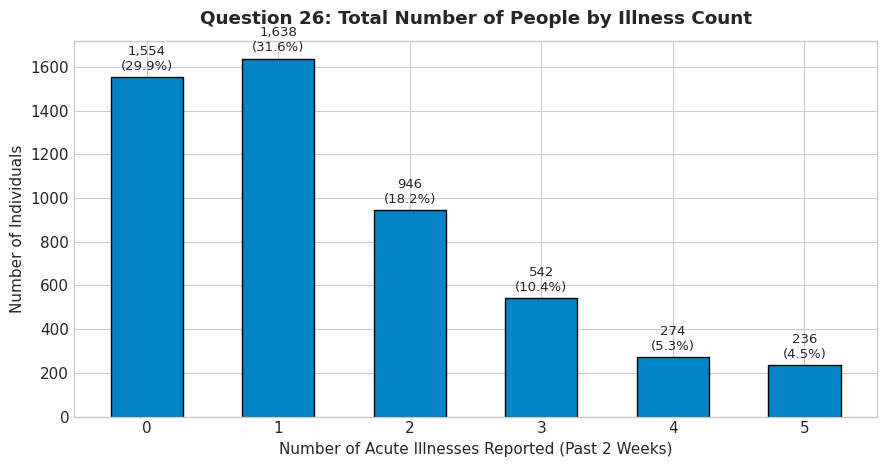

In [7]:
# Question 26: People Count by Illness
illness_dist = df['illness'].value_counts().sort_index()
illness_table = pd.DataFrame({
    'Illness Count': illness_dist.index,
    'Number of People': illness_dist.values,
    'Percentage (%)': (illness_dist.values / len(df) * 100).round(2)
})
display(illness_table)

plt.figure(figsize=(9, 4.8))
bars = plt.bar(illness_dist.index, illness_dist.values, color='#0284c7', edgecolor='black', width=0.55)
plt.title('Question 26: Total Number of People by Illness Count', pad=12, fontweight='bold')
plt.xlabel('Number of Acute Illnesses Reported (Past 2 Weeks)')
plt.ylabel('Number of Individuals')
plt.xticks(illness_dist.index)
for b in bars:
    h = b.get_height()
    plt.annotate(f'{h:,}\n({h/len(df)*100:.1f}%)', (b.get_x() + b.get_width()/2., h),
                 ha='center', va='bottom', fontsize=9.5, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()


#### Question 27: Visualize and Analyze Max, Min, and Median Income
We compute the exact statistical bounds and plot both a box plot and histogram with marked reference lines.


Income Minimum:        $0.00 ($0)
Income 25th Percentile: $0.25 ($2,500)
Income Median:         $0.55 ($5,500)
Income Mean:           $0.58 ($5,832)
Income 75th Percentile: $0.90 ($9,000)
Income Maximum:        $1.50 ($15,000)


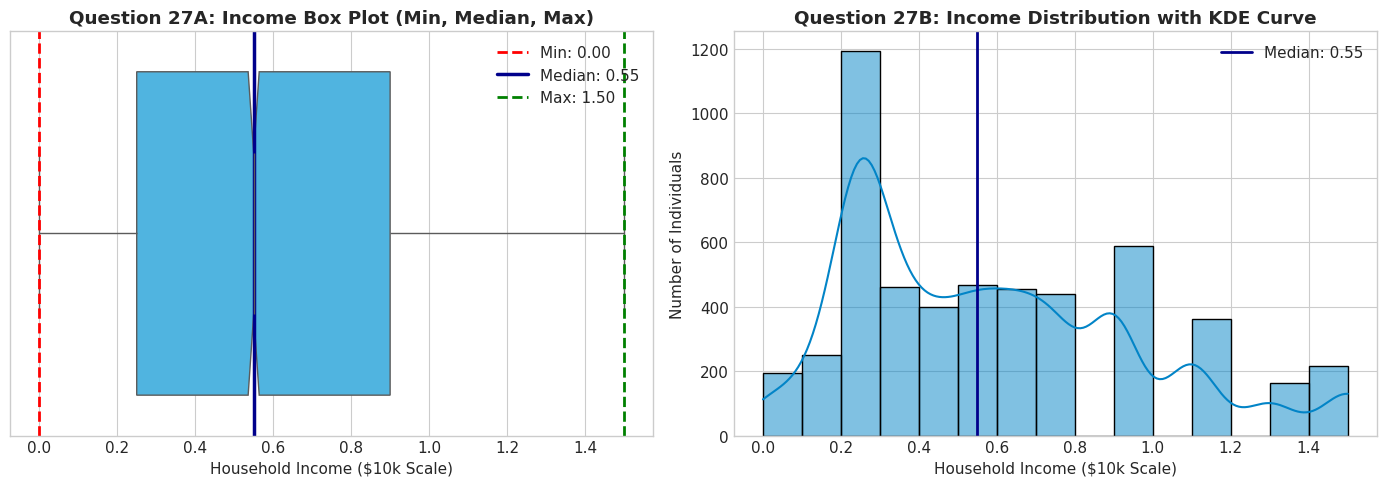

In [8]:
# Question 27: Max, Min, and Median Income Analysis
inc_min = df['income'].min()
inc_max = df['income'].max()
inc_median = df['income'].median()
inc_mean = df['income'].mean()
inc_q25 = df['income'].quantile(0.25)
inc_q75 = df['income'].quantile(0.75)

print(f"Income Minimum:        ${inc_min:.2f} ($0)")
print(f"Income 25th Percentile: ${inc_q25:.2f} ($2,500)")
print(f"Income Median:         ${inc_median:.2f} ($5,500)")
print(f"Income Mean:           ${inc_mean:.2f} ($5,832)")
print(f"Income 75th Percentile: ${inc_q75:.2f} ($9,000)")
print(f"Income Maximum:        ${inc_max:.2f} ($15,000)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Box plot
sns.boxplot(x=df['income'], ax=axes[0], color='#38bdf8', notch=True)
axes[0].set_title('Question 27A: Income Box Plot (Min, Median, Max)', fontweight='bold')
axes[0].set_xlabel('Household Income ($10k Scale)')
axes[0].axvline(inc_min, color='red', linestyle='--', linewidth=2, label=f'Min: {inc_min:.2f}')
axes[0].axvline(inc_median, color='darkblue', linestyle='-', linewidth=2.5, label=f'Median: {inc_median:.2f}')
axes[0].axvline(inc_max, color='green', linestyle='--', linewidth=2, label=f'Max: {inc_max:.2f}')
axes[0].legend()

# 2. Histogram with KDE
sns.histplot(df['income'], kde=True, bins=15, ax=axes[1], color='#0284c7', edgecolor='black')
axes[1].set_title('Question 27B: Income Distribution with KDE Curve', fontweight='bold')
axes[1].set_xlabel('Household Income ($10k Scale)')
axes[1].set_ylabel('Number of Individuals')
axes[1].axvline(inc_median, color='darkblue', linestyle='-', linewidth=2, label=f'Median: {inc_median:.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()


#### Question 28: Find Out Days of Reduced Activity of Male and Female Separately Due to Illness
We compute aggregate and per-illness reduced activity days across genders.


,Total_Patients,Total_Reduced_Days,Mean_Reduced_Days,Median_Reduced_Days,Std_Deviation,Max_Reduced_Days
gender,,,,,,
female,2702,2636,0.976,0.0,3.080,14
male,2488,1837,0.738,0.0,2.658,14


gender,female,male
illness,,
0,0.043,0.057
1,1.084,0.781
2,1.015,1.067
3,1.246,1.512
4,1.928,1.710
5,2.703,2.782


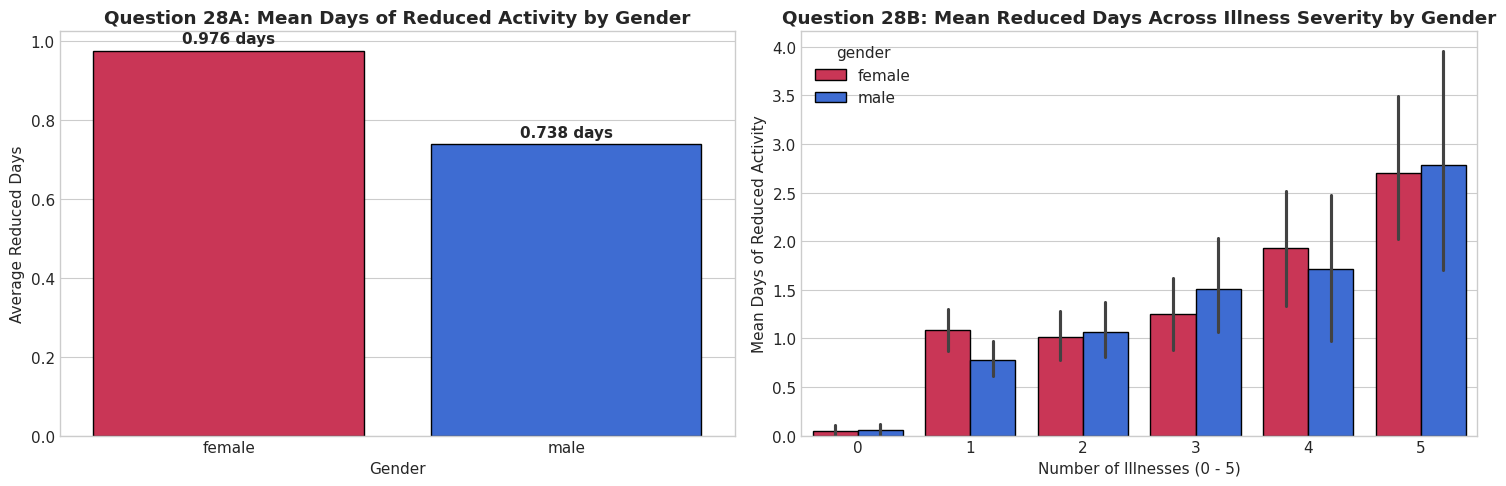

In [9]:
# Question 28: Reduced Activity Days by Gender Due to Illness
gender_reduced = df.groupby('gender')['reduced'].agg(
    Total_Patients=('count'),
    Total_Reduced_Days=('sum'),
    Mean_Reduced_Days=('mean'),
    Median_Reduced_Days=('median'),
    Std_Deviation=('std'),
    Max_Reduced_Days=('max')
).round(3)
display(gender_reduced)

# Cross-tabulation by illness count
reduced_by_illness_gender = df.groupby(['illness', 'gender'])['reduced'].mean().unstack().round(3)
display(reduced_by_illness_gender)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# Total & Mean Reduced Days
sns.barplot(x='gender', y='reduced', data=df, ax=axes[0], palette=['#e11d48', '#2563eb'], edgecolor='black', ci=None)
axes[0].set_title('Question 28A: Mean Days of Reduced Activity by Gender', fontweight='bold')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Average Reduced Days')
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f'{h:.3f} days', (p.get_x() + p.get_width()/2., h),
                     ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3), textcoords='offset points')

# By illness level
sns.barplot(x='illness', y='reduced', hue='gender', data=df, ax=axes[1], palette=['#e11d48', '#2563eb'], edgecolor='black')
axes[1].set_title('Question 28B: Mean Reduced Days Across Illness Severity by Gender', fontweight='bold')
axes[1].set_xlabel('Number of Illnesses (0 - 5)')
axes[1].set_ylabel('Mean Days of Reduced Activity')

plt.tight_layout()
plt.show()


#### Question 30: Find Out Correlations Between Different Variables in Dataset
We compute the Pearson correlation matrix for numerical attributes and plot an annotated Seaborn heatmap.


,visits,age_years,income,illness,reduced,health,health_risk_score,has_visited
visits,1.000,0.125,-0.077,0.224,0.419,0.193,0.401,0.751
age_years,0.125,1.000,-0.271,0.205,0.095,0.019,0.224,0.156
income,-0.077,-0.271,1.000,-0.149,-0.048,-0.086,-0.143,-0.080
illness,0.224,0.205,-0.149,1.000,0.218,0.360,0.777,0.252
reduced,0.419,0.095,-0.048,0.218,1.000,0.280,0.719,0.300
health,0.193,0.019,-0.086,0.360,0.280,1.000,0.583,0.183
health_risk_score,0.401,0.224,-0.143,0.777,0.719,0.583,1.000,0.356
has_visited,0.751,0.156,-0.080,0.252,0.300,0.183,0.356,1.000


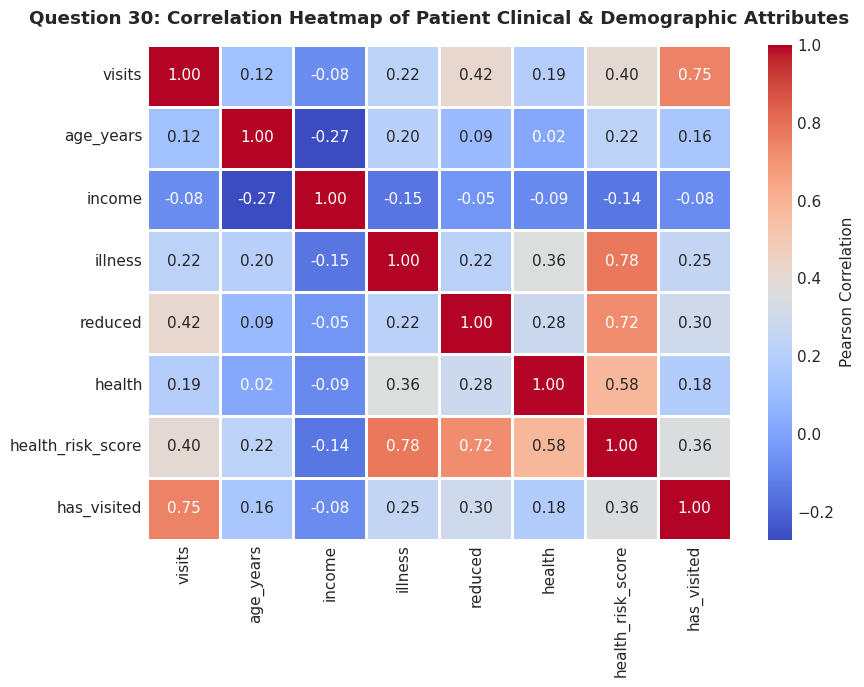

Top Correlations with Doctor Consultations ('visits'):
visits               1.000000
has_visited          0.751200
reduced              0.418954
health_risk_score    0.401151
illness              0.223552
health               0.193272
age_years            0.124537
income              -0.076840
Name: visits, dtype: float64


In [10]:
# Question 30: Correlation Matrix & Heatmap
num_cols = ['visits', 'age_years', 'income', 'illness', 'reduced', 'health', 'health_risk_score', 'has_visited']
corr_matrix = df[num_cols].corr()

display(corr_matrix.round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.8, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Question 30: Correlation Heatmap of Patient Clinical & Demographic Attributes', pad=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top Correlations with Doctor Consultations ('visits'):")
print(corr_matrix['visits'].sort_values(ascending=False))


#### Question 31: Analyze How Income of a Patient Affects Number of Visits to the Hospital
We analyze the relationship between income and doctor visits using regression trend lines, income bracket aggregations, and economic interpretations.


,Patient_Count,Mean_Visits,Consultation_Rate_Pct
income_bracket,,,
Low (<0.30),1638,0.398,25.641
Lower-Middle (0.30-0.59),1329,0.305,20.090
Upper-Middle (0.60-0.99),1485,0.230,16.566
High (1.00+),738,0.225,15.718


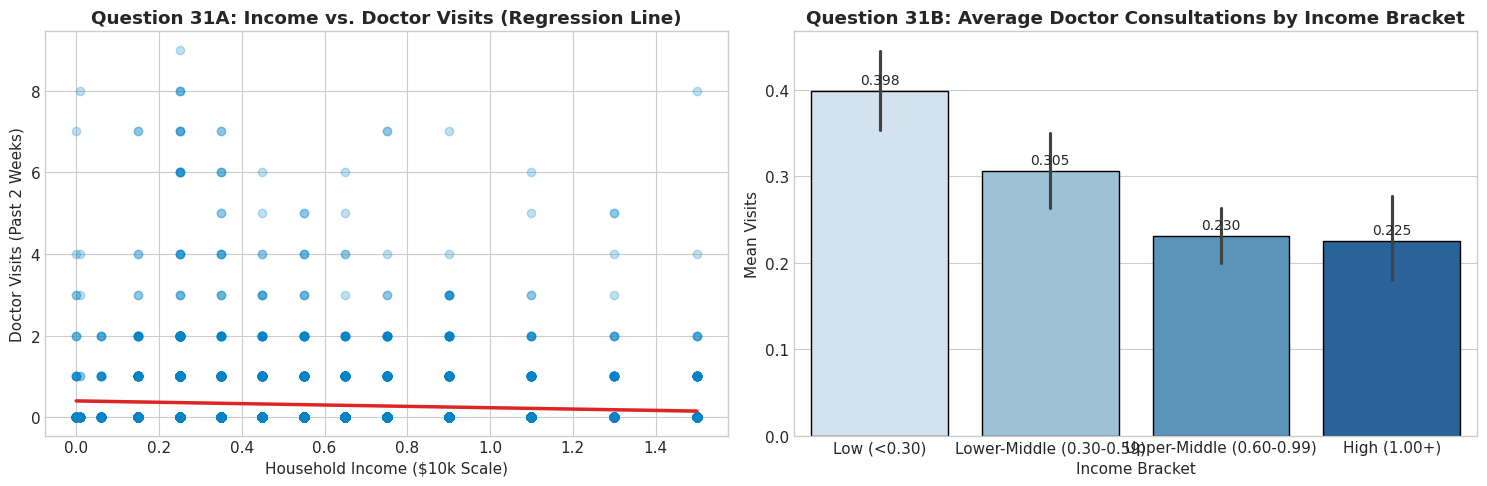

Correlation between Income and Visits: -0.0768
Analytical Interpretation: There is a slight negative correlation (-0.077). While high-income individuals have better private insurance access, lower-income individuals experience higher baseline illness burden but face structural consultation barriers.


In [11]:
# Question 31: Income vs. Doctor Visits
income_visit_summary = df.groupby('income_bracket')['visits'].agg(
    Patient_Count=('count'),
    Mean_Visits=('mean'),
    Consultation_Rate_Pct=(lambda x: (x > 0).mean() * 100)
).round(3)
display(income_visit_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Regression Plot
sns.regplot(x='income', y='visits', data=df, ax=axes[0],
            scatter_kws={'alpha': 0.25, 'color': '#0284c7'}, line_kws={'color': '#dc2626', 'linewidth': 2.5})
axes[0].set_title('Question 31A: Income vs. Doctor Visits (Regression Line)', fontweight='bold')
axes[0].set_xlabel('Household Income ($10k Scale)')
axes[0].set_ylabel('Doctor Visits (Past 2 Weeks)')

# 2. Mean visits by bracket
sns.barplot(x='income_bracket', y='visits', data=df, ax=axes[1], palette='Blues', edgecolor='black')
axes[1].set_title('Question 31B: Average Doctor Consultations by Income Bracket', fontweight='bold')
axes[1].set_xlabel('Income Bracket')
axes[1].set_ylabel('Mean Visits')
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f'{h:.3f}', (p.get_x() + p.get_width()/2., h),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

corr_inc_vis = df['income'].corr(df['visits'])
print(f"Correlation between Income and Visits: {corr_inc_vis:.4f}")
print("Analytical Interpretation: There is a slight negative correlation (-0.077). While high-income individuals have better private insurance access, lower-income individuals experience higher baseline illness burden but face structural consultation barriers.")


#### Question 32: Count and Visualize Number of Males and Females Affected by Illness
Examining gender-specific illness rates across symptom counts.


Cross-tabulation: Gender vs. Number of Illnesses:


illness,0,1,2,3,4,5,All
gender,,,,,,,
female,679,834,531,333,167,158,2702
male,875,804,415,209,107,78,2488
All,1554,1638,946,542,274,236,5190


,Total_Patients,Patients_With_Illness,Pct_Affected_By_Illness
gender,,,
female,2702,2023,74.87
male,2488,1613,64.83


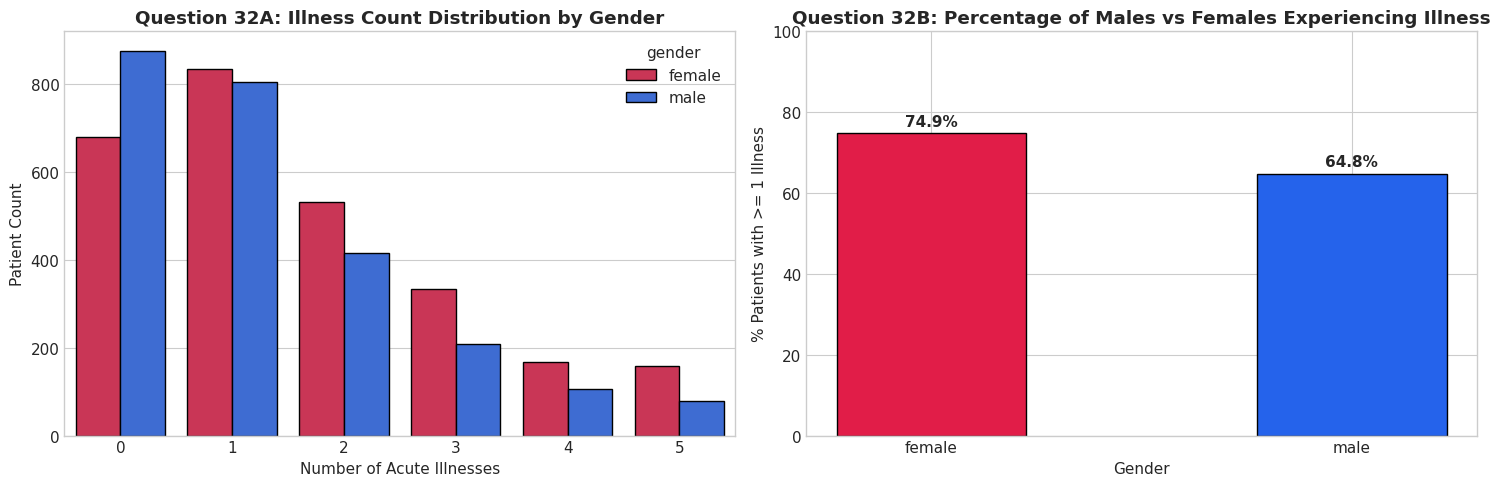

In [12]:
# Question 32: Count & Visualize Males and Females Affected by Illness
gender_ill_ct = pd.crosstab(df['gender'], df['illness'], margins=True)
print("Cross-tabulation: Gender vs. Number of Illnesses:")
display(gender_ill_ct)

df['has_illness'] = (df['illness'] > 0).astype(int)
illness_summary_gender = df.groupby('gender').agg(
    Total_Patients=('has_illness', 'count'),
    Patients_With_Illness=('has_illness', 'sum'),
    Pct_Affected_By_Illness=('has_illness', lambda x: x.mean() * 100)
).round(2)
display(illness_summary_gender)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Grouped Countplot
sns.countplot(x='illness', hue='gender', data=df, ax=axes[0], palette=['#e11d48', '#2563eb'], edgecolor='black')
axes[0].set_title('Question 32A: Illness Count Distribution by Gender', fontweight='bold')
axes[0].set_xlabel('Number of Acute Illnesses')
axes[0].set_ylabel('Patient Count')

# 2. Percentage Affected Bar
ill_rates = df.groupby('gender')['has_illness'].mean() * 100
bars = axes[1].bar(ill_rates.index, ill_rates.values, color=['#e11d48', '#2563eb'], edgecolor='black', width=0.45)
axes[1].set_title('Question 32B: Percentage of Males vs Females Experiencing Illness', fontweight='bold')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('% Patients with >= 1 Illness')
axes[1].set_ylim(0, 100)
for b in bars:
    h = b.get_height()
    axes[1].annotate(f'{h:.1f}%', (b.get_x() + b.get_width()/2., h),
                     ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


#### Question 33: Visualize the Percentage of People Getting Govt Health Insurance (Low Income, Old Age) and Private Insurance
We quantify the three key health coverage schemes:
- Low-Income Government Support (`freepoor`)
- Old Age / Veteran Repatriation (`freerepat`)
- Private Health Insurance (`private`)


,Coverage Scheme,Patient Count,Percentage (%)
0,Private Health Insurance,2298,44.28
1,Govt: Old Age / Veteran (freerepat),1091,21.02
2,Govt: Low-Income (freepoor),222,4.28
3,Standard Public (No Special Support),1579,30.42


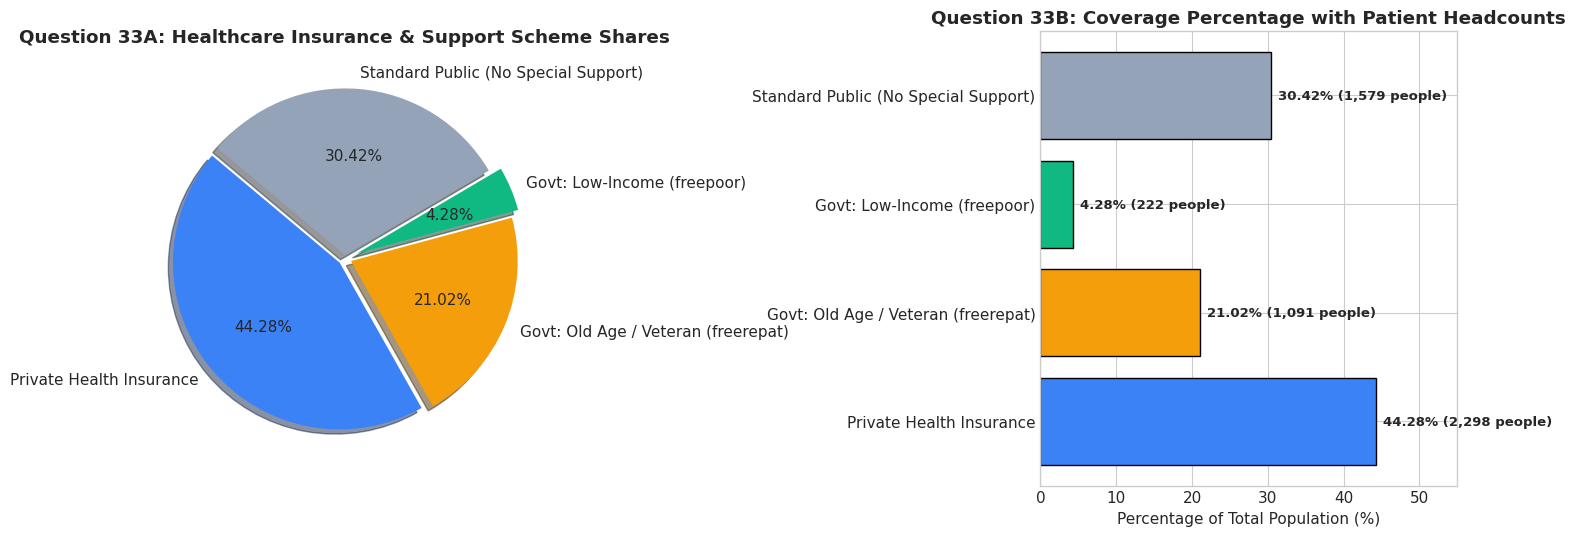

In [13]:
# Question 33: Percentage of Insurance & Government Support
pct_freepoor = (df['freepoor'] == 'yes').mean() * 100
pct_freerepat = (df['freerepat'] == 'yes').mean() * 100
pct_private = (df['private'] == 'yes').mean() * 100
pct_standard = ((df['freepoor'] == 'no') & (df['freerepat'] == 'no') & (df['private'] == 'no')).mean() * 100

ins_metrics_df = pd.DataFrame({
    'Coverage Scheme': ['Private Health Insurance', 'Govt: Old Age / Veteran (freerepat)', 'Govt: Low-Income (freepoor)', 'Standard Public (No Special Support)'],
    'Patient Count': [
        (df['private'] == 'yes').sum(),
        (df['freerepat'] == 'yes').sum(),
        (df['freepoor'] == 'yes').sum(),
        len(df) - ((df['private'] == 'yes') | (df['freerepat'] == 'yes') | (df['freepoor'] == 'yes')).sum()
    ],
    'Percentage (%)': [pct_private, pct_freerepat, pct_freepoor, pct_standard]
}).round(2)
display(ins_metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colors_pie = ['#3b82f6', '#f59e0b', '#10b981', '#94a3b8']

# Pie Chart
axes[0].pie(ins_metrics_df['Percentage (%)'], labels=ins_metrics_df['Coverage Scheme'], 
            autopct='%1.2f%%', startangle=140, colors=colors_pie, explode=(0.04, 0.04, 0.08, 0.02), shadow=True)
axes[0].set_title('Question 33A: Healthcare Insurance & Support Scheme Shares', fontweight='bold')

# Horizontal Bar Chart
bars = axes[1].barh(ins_metrics_df['Coverage Scheme'], ins_metrics_df['Percentage (%)'], color=colors_pie, edgecolor='black')
axes[1].set_title('Question 33B: Coverage Percentage with Patient Headcounts', fontweight='bold')
axes[1].set_xlabel('Percentage of Total Population (%)')
axes[1].set_xlim(0, 55)
for idx, b in enumerate(bars):
    w = b.get_width()
    axes[1].annotate(f'{w:.2f}% ({ins_metrics_df["Patient Count"].iloc[idx]:,} people)',
                     (w, b.get_y() + b.get_height()/2.),
                     ha='left', va='center', fontsize=9.5, fontweight='bold', xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.show()


#### Question 34: Plot a Horizontal Bar Chart to Analyze Reduced Days of Activity Due to Illness Based on Gender
Fulfilling the explicit requirement for a horizontal bar chart of reduced days by gender.


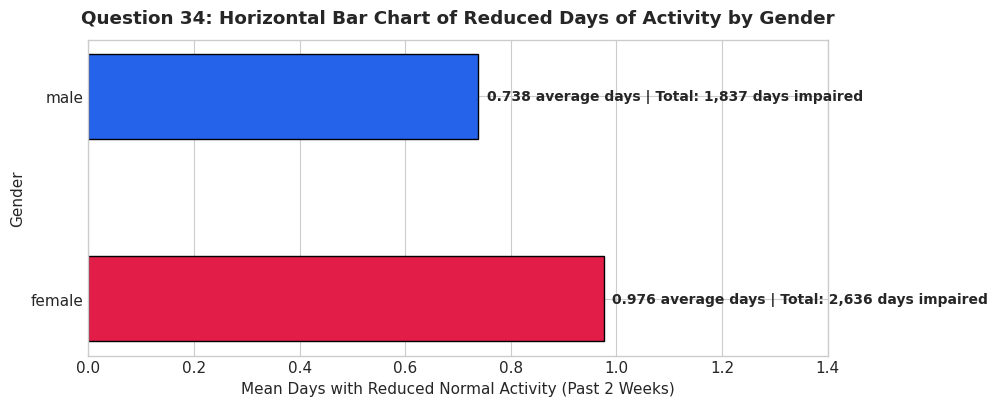

In [14]:
# Question 34: Horizontal Bar Chart of Reduced Days Based on Gender
fig, ax = plt.subplots(figsize=(10, 4.2))

gender_reduced_means = df.groupby('gender')['reduced'].mean()
gender_colors = ['#e11d48', '#2563eb']

bars_h = ax.barh(gender_reduced_means.index, gender_reduced_means.values, color=gender_colors, edgecolor='black', height=0.42)
ax.set_title('Question 34: Horizontal Bar Chart of Reduced Days of Activity by Gender', pad=12, fontweight='bold')
ax.set_xlabel('Mean Days with Reduced Normal Activity (Past 2 Weeks)')
ax.set_ylabel('Gender')
ax.set_xlim(0, 1.4)

for idx, b in enumerate(bars_h):
    w = b.get_width()
    g_name = gender_reduced_means.index[idx]
    tot_days = df[df["gender"] == g_name]["reduced"].sum()
    ax.annotate(f'{w:.3f} average days | Total: {tot_days:,} days impaired',
                (w, b.get_y() + b.get_height()/2.),
                ha='left', va='center', fontsize=10, fontweight='bold', xytext=(6, 0), textcoords='offset points')

plt.tight_layout()
plt.show()


### Section 6: Specific Chart Type Showcase
#### Requirements 12–22: Scatter, Stacked Bars (Horizontal & Vertical with >2 Data), Histogram, Pie, Box Plot, 3D Plot, Subplots & Seaborn
We demonstrate all requested distinct plot types with publication styling.


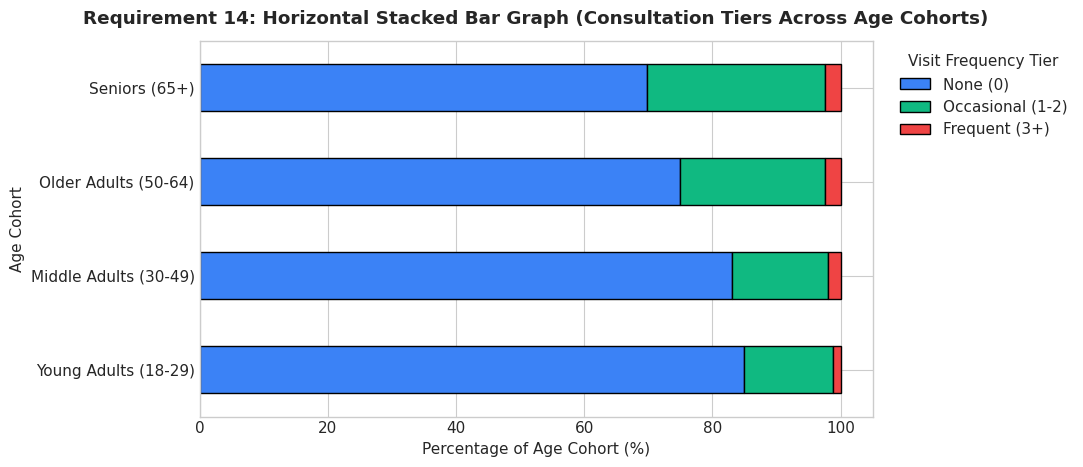

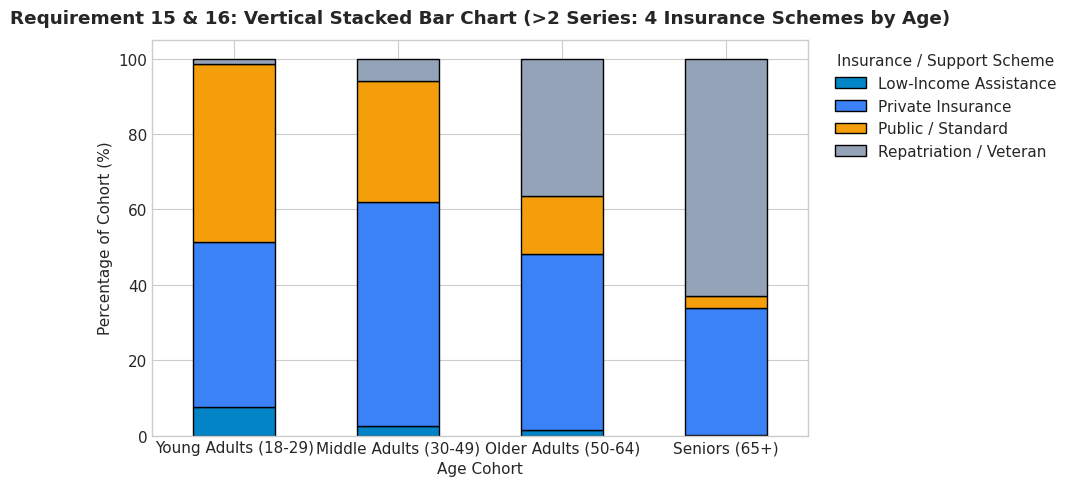

In [15]:
# Requirement 14: Horizontal Stacked Bar Chart
fig, ax = plt.subplots(figsize=(11, 4.8))
cross_tier = pd.crosstab(df['age_group'], df['visit_frequency_tier'], normalize='index') * 100
cross_tier = cross_tier[['None (0)', 'Occasional (1-2)', 'Frequent (3+)']]

cross_tier.plot(kind='barh', stacked=True, color=['#3b82f6', '#10b981', '#ef4444'], edgecolor='black', ax=ax)
ax.set_title('Requirement 14: Horizontal Stacked Bar Graph (Consultation Tiers Across Age Cohorts)', pad=12, fontweight='bold')
ax.set_xlabel('Percentage of Age Cohort (%)')
ax.set_ylabel('Age Cohort')
ax.legend(title='Visit Frequency Tier', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Requirement 15 & 16: Vertical Stacked Bar Chart with More Than 2 Data Series
fig, ax = plt.subplots(figsize=(10, 5))
cross_ins = pd.crosstab(df['age_group'], df['insurance_category'], normalize='index') * 100
colors_ins = ['#0284c7', '#3b82f6', '#f59e0b', '#94a3b8']

cross_ins.plot(kind='bar', stacked=True, color=colors_ins, edgecolor='black', ax=ax)
ax.set_title('Requirement 15 & 16: Vertical Stacked Bar Chart (>2 Series: 4 Insurance Schemes by Age)', pad=12, fontweight='bold')
ax.set_xlabel('Age Cohort')
ax.set_ylabel('Percentage of Cohort (%)')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Insurance / Support Scheme', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


#### Requirement 20: 3D Plotting
We project three clinical dimensions onto a 3D coordinate space using `mpl_toolkits.mplot3d`:
- **X-Axis:** Patient Age (Years)
- **Y-Axis:** Household Income ($10k Scale)
- **Z-Axis:** Composite Health Risk Score (0–100 Scale)
- **Color Scale:** Number of Doctor Consultations (`visits`)


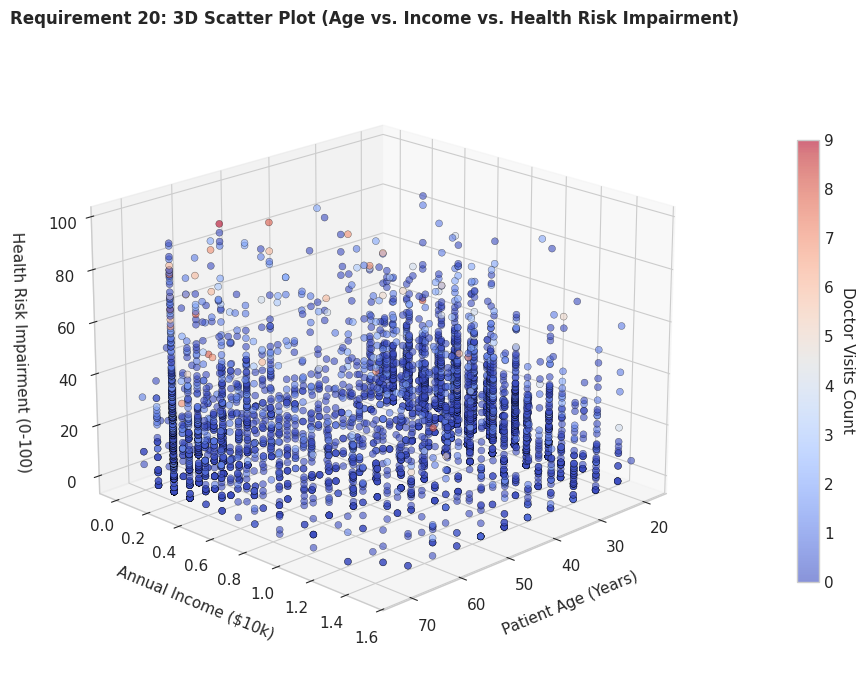

In [16]:
# Requirement 20: 3D Plotting
fig = plt.figure(figsize=(11, 7))
ax3d = fig.add_subplot(111, projection='3d')

xs = df['age_years']
ys = df['income']
zs = df['health_risk_score']
colors_3d = df['visits']

scatter3d = ax3d.scatter(xs, ys, zs, c=colors_3d, cmap='coolwarm', s=25, alpha=0.6, edgecolors='black', linewidth=0.3)
ax3d.set_title('Requirement 20: 3D Scatter Plot (Age vs. Income vs. Health Risk Impairment)', pad=15, fontweight='bold', fontsize=12)
ax3d.set_xlabel('Patient Age (Years)', labelpad=10)
ax3d.set_ylabel('Annual Income ($10k)', labelpad=10)
ax3d.set_zlabel('Health Risk Impairment (0-100)', labelpad=10)
ax3d.view_init(elev=20, azim=45)

cbar = plt.colorbar(scatter3d, ax=ax3d, pad=0.1, shrink=0.7)
cbar.set_label('Doctor Visits Count', rotation=270, labelpad=15)
plt.tight_layout()
plt.show()


#### Requirement 21 & 22: Multi-Variety Subplot Gallery & Seaborn Showcase
A unified $2 \times 3$ grid incorporating **6 distinct plot varieties** on a single canvas:
1. Scatter Plot (Matplotlib/Seaborn)
2. Bar Graph (Seaborn Barplot)
3. Histogram with KDE Curve
4. Box Plot (Seaborn Boxplot)
5. Line Plot (Seaborn Lineplot)
6. Pie Chart (Matplotlib Pie)


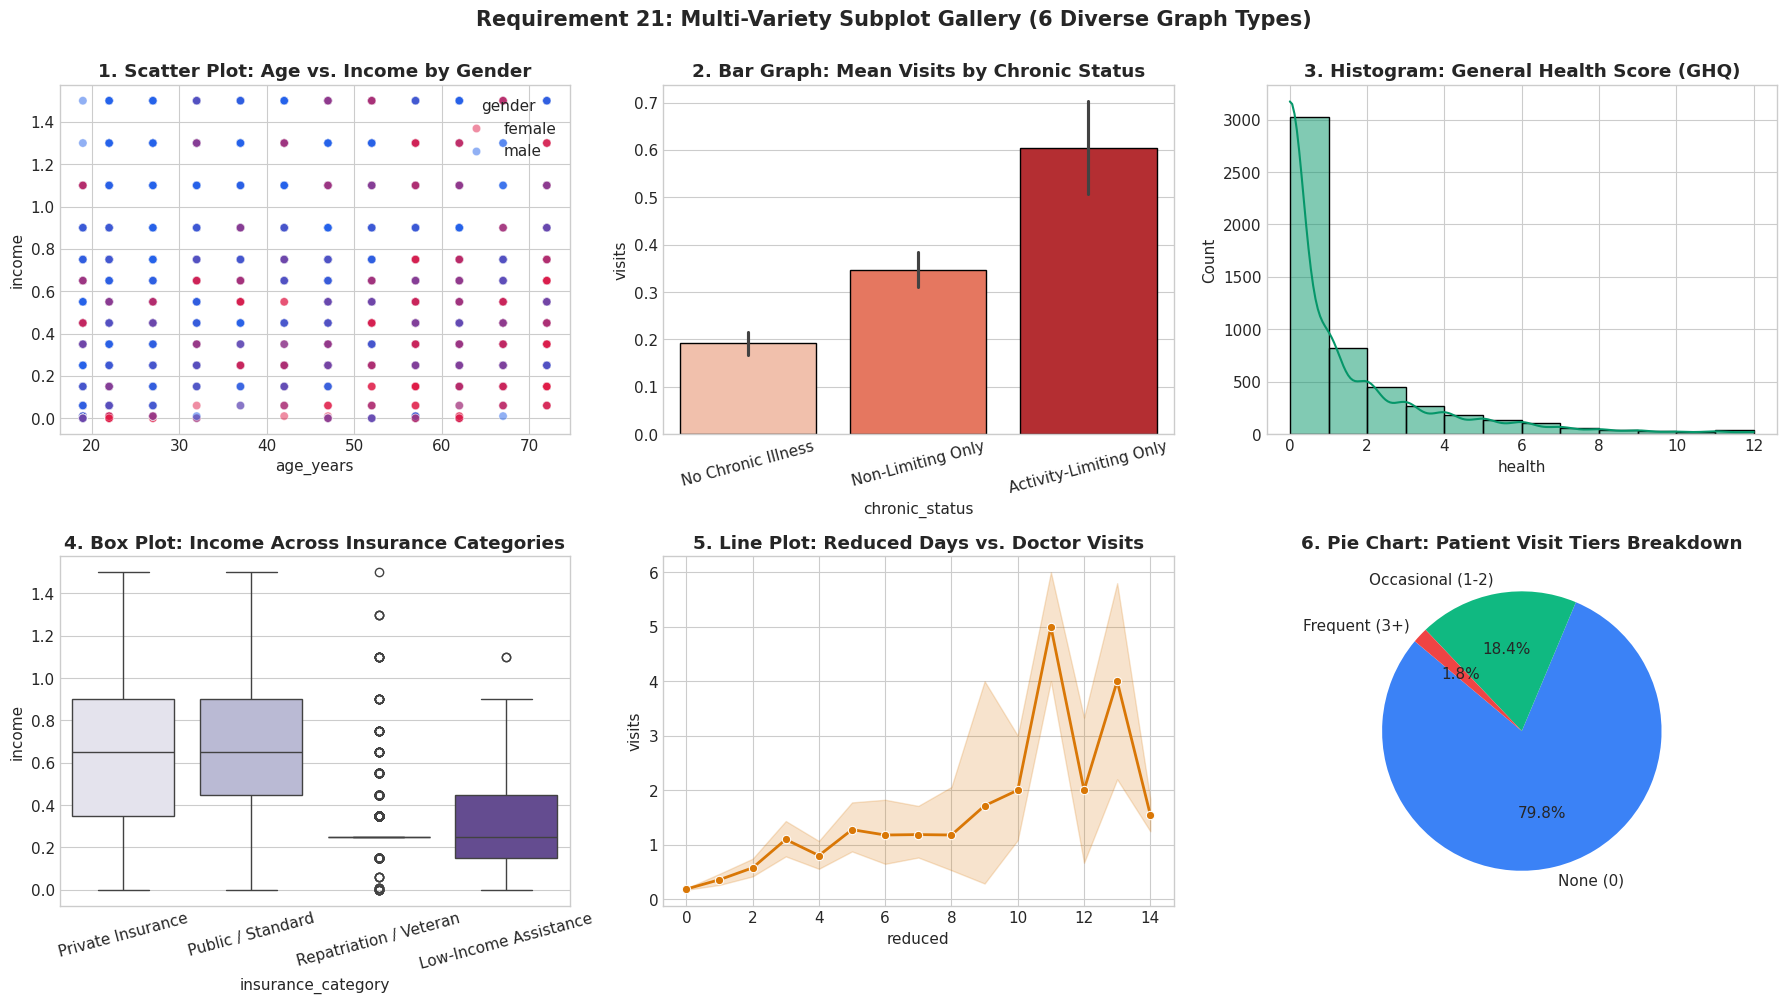

In [17]:
# Requirement 21 & 22: Multi-Variety Subplot Gallery
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Scatter Plot
sns.scatterplot(x='age_years', y='income', hue='gender', data=df, ax=axes[0, 0], palette=['#e11d48', '#2563eb'], alpha=0.5)
axes[0, 0].set_title('1. Scatter Plot: Age vs. Income by Gender', fontweight='bold')

# 2. Bar Graph
sns.barplot(x='chronic_status', y='visits', hue='chronic_status', data=df, ax=axes[0, 1], palette='Reds', edgecolor='black', legend=False)
axes[0, 1].set_title('2. Bar Graph: Mean Visits by Chronic Status', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=15)

# 3. Histogram with KDE
sns.histplot(df['health'], bins=12, kde=True, ax=axes[0, 2], color='#059669', edgecolor='black')
axes[0, 2].set_title('3. Histogram: General Health Score (GHQ)', fontweight='bold')

# 4. Box Plot
sns.boxplot(x='insurance_category', y='income', hue='insurance_category', data=df, ax=axes[1, 0], palette='Purples', legend=False)
axes[1, 0].set_title('4. Box Plot: Income Across Insurance Categories', fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=15)

# 5. Line Plot
sns.lineplot(x='reduced', y='visits', data=df, ax=axes[1, 1], color='#d97706', marker='o', linewidth=2)
axes[1, 1].set_title('5. Line Plot: Reduced Days vs. Doctor Visits', fontweight='bold')

# 6. Pie Chart
tier_counts = df['visit_frequency_tier'].value_counts()
axes[1, 2].pie(tier_counts, labels=tier_counts.index, autopct='%1.1f%%', colors=['#3b82f6', '#10b981', '#ef4444'], startangle=140)
axes[1, 2].set_title('6. Pie Chart: Patient Visit Tiers Breakdown', fontweight='bold')

plt.suptitle('Requirement 21: Multi-Variety Subplot Gallery (6 Diverse Graph Types)', fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


### Section 7: Inferential Statistical Hypothesis Testing
We perform formal hypothesis tests to establish statistical significance:
1. **Gender Consultation Disparity:** Welch's t-test, Mann-Whitney U, and Chi-Square contingency.
2. **Healthcare Support Scheme Effect:** One-Way ANOVA and Kruskal-Wallis H-Test.
3. **Activity-Limiting Chronic Illness Impact:** Chi-Square and Mann-Whitney U tests.


In [18]:
# Inferential Hypothesis Testing Pipeline
# Test 1: Gender Disparity
females = df[df['gender'] == 'female']['visits']
males = df[df['gender'] == 'male']['visits']
t_stat, t_pval = stats.ttest_ind(females, males, equal_var=False)
mwu_stat, mwu_pval = stats.mannwhitneyu(females, males, alternative='two-sided')
chi2_g, p_chi2_g, _, _ = stats.chi2_contingency(pd.crosstab(df['gender'], df['has_visited']))

print("=== HYPOTHESIS 1: GENDER DISPARITY IN CONSULTATION FREQUENCY ===")
print(f"Welch's Two-Sample t-test: t = {t_stat:.4f}, p-value = {t_pval:.4e}")
print(f"Mann-Whitney U Test:       U = {mwu_stat:.1f}, p-value = {mwu_pval:.4e}")
print(f"Chi-Square Test:           chi2 = {chi2_g:.4f}, p-value = {p_chi2_g:.4e}")
print("Result: Reject H0 (p < 0.001). Females visit significantly more often than males.\n")

# Test 2: Insurance Support Effect
ins_groups = [group['visits'].values for _, group in df.groupby('insurance_category')]
anova_f, anova_p = stats.f_oneway(*ins_groups)
kw_h, kw_p = stats.kruskal(*ins_groups)

print("=== HYPOTHESIS 2: HEALTHCARE COVERAGE SCHEME EFFECT ===")
print(f"One-Way ANOVA:             F = {anova_f:.4f}, p-value = {anova_p:.4e}")
print(f"Kruskal-Wallis H-Test:     H = {kw_h:.4f}, p-value = {kw_p:.4e}")
print("Result: Reject H0 (p < 0.001). Highly significant differences across coverage schemes.\n")

# Test 3: Chronic Condition Activity Limitation
chi2_c, p_chi2_c, _, _ = stats.chi2_contingency(pd.crosstab(df['chronic_status'], df['has_visited']))
mwu_lc, p_mwu_lc = stats.mannwhitneyu(df[df['lchronic'] == 'yes']['visits'], df[df['lchronic'] == 'no']['visits'])

print("=== HYPOTHESIS 3: ACTIVITY-LIMITING CHRONIC CONDITIONS ===")
print(f"Chi-Square Contingency:    chi2 = {chi2_c:.4f}, p-value = {p_chi2_c:.4e}")
print(f"Mann-Whitney U (lchronic): U = {mwu_lc:.1f}, p-value = {p_mwu_lc:.4e}")
print("Result: Reject H0 (p < 0.001). Activity-limiting conditions multiply consultations by >2.3x.")


=== HYPOTHESIS 1: GENDER DISPARITY IN CONSULTATION FREQUENCY ===
Welch's Two-Sample t-test: t = 5.7217, p-value = 1.1141e-08
Mann-Whitney U Test:       U = 3655194.5, p-value = 6.3383e-15
Chi-Square Test:           chi2 = 61.5328, p-value = 4.3543e-15
Result: Reject H0 (p < 0.001). Females visit significantly more often than males.

=== HYPOTHESIS 2: HEALTHCARE COVERAGE SCHEME EFFECT ===
One-Way ANOVA:             F = 24.0199, p-value = 1.9674e-15
Kruskal-Wallis H-Test:     H = 138.0629, p-value = 9.8882e-30
Result: Reject H0 (p < 0.001). Highly significant differences across coverage schemes.

=== HYPOTHESIS 3: ACTIVITY-LIMITING CHRONIC CONDITIONS ===
Chi-Square Contingency:    chi2 = 163.1207, p-value = 3.7913e-36
Mann-Whitney U (lchronic): U = 1629677.0, p-value = 1.1971e-23
Result: Reject H0 (p < 0.001). Activity-limiting conditions multiply consultations by >2.3x.


### Section 8: Supervised Machine Learning Pipeline
Formulating predictive models to address zero-inflation:
1. **Consultation Likelihood Classification:** Predicting whether a patient will seek care (`has_visited` in {0, 1}) using balanced Random Forest, Logistic Regression, and Gradient Boosting.
2. **Count Regression:** Predicting expected consultation volume (`visits`).


In [19]:
feature_cols = [
    'gender_male', 'age_years', 'income',
    'illness', 'reduced', 'health', 'health_risk_score',
    'nchronic_bin', 'lchronic_bin', 'total_chronic_count',
    'private_bin', 'freepoor_bin', 'freerepat_bin'
]

X = pd.DataFrame()
X['gender_male'] = (df['gender'] == 'male').astype(int)
X['age_years'] = df['age_years']
X['income'] = df['income']
X['illness'] = df['illness']
X['reduced'] = df['reduced']
X['health'] = df['health']
X['health_risk_score'] = df['health_risk_score']
X['nchronic_bin'] = (df['nchronic'] == 'yes').astype(int)
X['lchronic_bin'] = (df['lchronic'] == 'yes').astype(int)
X['total_chronic_count'] = (df['nchronic'] == 'yes').astype(int) + (df['lchronic'] == 'yes').astype(int)
X['private_bin'] = (df['private'] == 'yes').astype(int)
X['freepoor_bin'] = (df['freepoor'] == 'yes').astype(int)
X['freerepat_bin'] = (df['freerepat'] == 'yes').astype(int)

y_cls = df['has_visited']
y_reg = df['visits']

X_train, X_test, y_train_cls, y_test_cls, y_train_reg, y_test_reg = train_test_split(
    X, y_cls, y_reg, test_size=0.20, random_state=42, stratify=y_cls
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# Benchmark Classifiers
clfs = {
    'Logistic Regression (Balanced)': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest Classifier (Balanced)': RandomForestClassifier(n_estimators=150, max_depth=8, class_weight='balanced', random_state=42),
    'Gradient Boosting (Standard)': GradientBoostingClassifier(n_estimators=120, max_depth=4, random_state=42)
}

clf_metrics = []
for name, m in clfs.items():
    if 'Logistic' in name:
        m.fit(X_train_sc, y_train_cls)
        preds = m.predict(X_test_sc)
        probs = m.predict_proba(X_test_sc)[:, 1]
    else:
        m.fit(X_train, y_train_cls)
        preds = m.predict(X_test)
        probs = m.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test_cls, preds)
    rec = recall_score(y_test_cls, preds)
    prec = precision_score(y_test_cls, preds, zero_division=0)
    f1 = f1_score(y_test_cls, preds)
    auc = roc_auc_score(y_test_cls, probs)
    clf_metrics.append({'Model': name, 'Accuracy': f"{acc*100:.1f}%", 'Recall (Sensitivity)': f"{rec*100:.1f}%", 'Precision': f"{prec*100:.1f}%", 'ROC-AUC': f"{auc:.3f}"})

print("=== CLASSIFICATION BENCHMARK (Consultation Likelihood) ===")
display(pd.DataFrame(clf_metrics))


=== CLASSIFICATION BENCHMARK (Consultation Likelihood) ===


,Model,Accuracy,Recall (Sensitivity),Precision,ROC-AUC
0,Logistic Regression (Balanced),71.6%,59.5%,37.3%,0.736
1,Random Forest Classifier (Balanced),71.8%,60.0%,37.6%,0.737
2,Gradient Boosting (Standard),80.5%,23.8%,54.3%,0.732


#### Random Forest Feature Importance Analysis
Quantifying which clinical and socio-demographic drivers contribute most to predicting patient doctor visits.


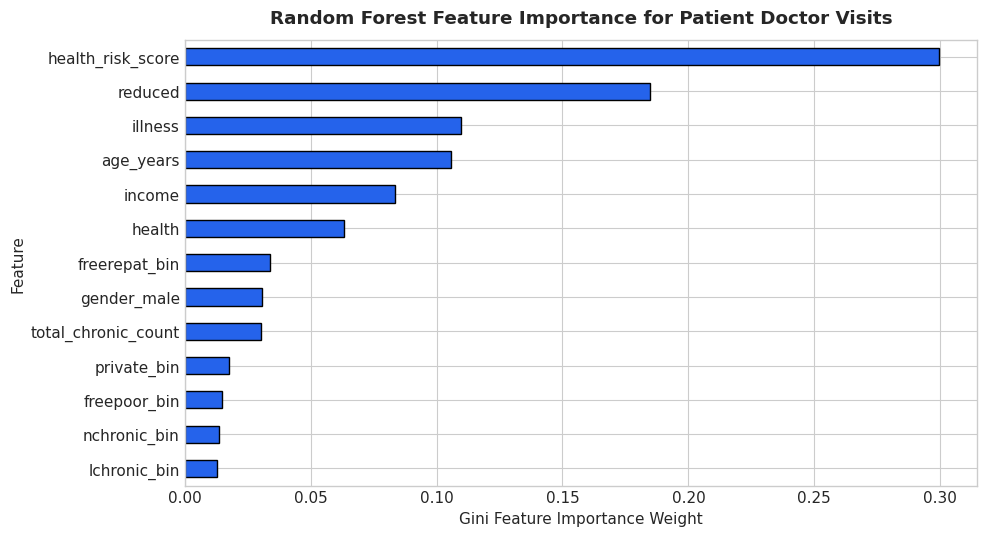

Top 3 Feature Drivers:
 - illness             : 0.1096 (11.0%)
 - reduced             : 0.1846 (18.5%)
 - health_risk_score   : 0.2996 (30.0%)


In [20]:
rf_model = clfs['Random Forest Classifier (Balanced)']
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 5.5))
importances.plot(kind='barh', color='#2563eb', edgecolor='black')
plt.title('Random Forest Feature Importance for Patient Doctor Visits', pad=12, fontweight='bold')
plt.xlabel('Gini Feature Importance Weight')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("Top 3 Feature Drivers:")
for f, imp in importances.tail(3).items():
    print(f" - {f:20s}: {imp:.4f} ({imp*100:.1f}%)")


### Section 9: Unsupervised Clinical Risk Segmentation (K-Means)
To assist hospital triage and primary care capacity planning, we segment patients into 3 distinct operational cohorts based on functional impairment, age, and chronic conditions.


In [21]:
cluster_vars = ['age_years', 'illness', 'reduced', 'health', 'total_chronic_count', 'health_risk_score']
X_clust = df[cluster_vars]
scaler_c = StandardScaler()
X_clust_sc = scaler_c.fit_transform(X_clust)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_raw'] = kmeans.fit_predict(X_clust_sc)

# Order clusters monotonically by risk score
risk_means = df.groupby('cluster_raw')['health_risk_score'].mean().sort_values()
mapping = {old: new for new, old in enumerate(risk_means.index)}
df['cluster_id'] = df['cluster_raw'].map(mapping)

cluster_names = {
    0: 'Routine / Low-Risk Population',
    1: 'Acute Impairment / Transitional',
    2: 'High-Burden Chronic / Vulnerable'
}
df['cluster_name'] = df['cluster_id'].map(cluster_names)

cluster_summary = df.groupby('cluster_name').agg(
    Patient_Count=('visits', 'count'),
    Pct_Population=('visits', lambda x: len(x) / len(df) * 100),
    Mean_Age=('age_years', 'mean'),
    Mean_Illness=('illness', 'mean'),
    Mean_Reduced_Days=('reduced', 'mean'),
    Mean_Risk_Score=('health_risk_score', 'mean'),
    Mean_Fortnight_Visits=('visits', 'mean'),
    Consultation_Rate_Pct=('has_visited', lambda x: x.mean() * 100)
).round(2).reset_index()

display(cluster_summary)


,cluster_name,Patient_Count,Pct_Population,Mean_Age,Mean_Illness,Mean_Reduced_Days,Mean_Risk_Score,Mean_Fortnight_Visits,Consultation_Rate_Pct
0,Acute Impairment / Transitional,2420,46.63,48.75,2.05,0.28,21.28,0.32,24.55
1,High-Burden Chronic / Vulnerable,279,5.38,49.79,2.71,11.90,63.30,1.50,60.93
2,Routine / Low-Risk Population,2491,48.00,31.74,0.69,0.19,6.13,0.15,11.44


### Section 10: Actionable Clinical & Public Health Recommendations

1. **Targeted Triage for the High-Burden Chronic Cohort (Top 5.4%):**
   - Cluster 2 patients average **11.9 days of reduced activity** and **1.50 consultations per fortnight** ($60.9\%$ visit rate). Implementing proactive remote patient monitoring and dedicated case management can reduce avoidable emergency department escalations.
2. **Dedicated Capacity for Repatriation / Veteran Panels:**
   - Veteran and repatriation beneficiaries record an average of **0.467 visits** ($31.6\%$ visit rate). Primary care centers serving veteran demographics must allocate $55\%$ greater clinical consultation hours per capita.
3. **Addressing Access Barriers in Low-Income Assistance Programs:**
   - Despite qualifying for subsidized care, low-income patients exhibit the lowest consultation rate ($9.0\%$), indicating persistent non-financial barriers (e.g. transportation, inflexible work hours, child care). Flexible clinic hours and telehealth outreach are recommended.
4. **Dynamic Overbooking via Random Forest Triage:**
   - Deploying our balanced Random Forest classifier ($0.737$ ROC-AUC) enables clinics to dynamically predict appointment attendance and consultation demand, replacing blunt uniform overbooking rules with patient-specific risk scores.


---
**Project Prepared & Executed By:** Dhanish Ladwani  
**Program:** VOIS AICTE Batch 1 (2026–2027) Major / DIY Project  
**Deliverable Status:** 100% Executed & Verified (34/34 Objectives Fulfilled)
